In [40]:
 ### ARTS as the line-by-line code
import os
# set global variables BEFORE importing ARTS
os.environ['ARTS_DATA_PATH'] = '../arts-cat-data-2.6.14:../arts-xml-data-2.6.14'

import pyarts
from pyarts.arts import convert
# the fluxsim module
import FluxSimulator as fsm
import seaborn as sns


# helper packages
import numpy as np
import xarray as xr
from scipy.constants import speed_of_light as c
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import matplotlib.colors as colors


import typhon
import typhon.constants as tpc
import helper_funcs as hf
import pandas as pd
import cartopy.crs as ccrs


from scipy.optimize import minimize

plt.style.use('figsettings.mplstyle')

from cycler import cycler

from numpy.polynomial.legendre import legval
from numpy import meshgrid, deg2rad, gradient, cos



### Fig. 1
Phase function of four different ice habits.

In [4]:
### helper functions to calculate the effective radius

def re_from_iwc_A(A, IWC):
    """
    calculate effective radius from ice water content and projected particle area
    IN:
        A [m^-1]: the total projected area of the
            particles per unit volume of air
        IWC [kg/m^3]: ice water content
    OUT:
        re [\mum]: effective radius
    """
    return (3/4)*(IWC/(917 * A))    


def find_reff_ARTS(la, scatterer_name, idx_range, weight_cut = None):
    """
    calculate the effective radius, and the phase function using ARTS
    FluxSimulator module (modified).
    IN: 
        la: lambda parameter for the modified PSD
        scatterer_name [str]: which ARTS optical file to read from
        idx_range [int]: number of elements (object sizes) to read
        weight_cut [int]: patch in case the phrase function and object size
            metadata are different (aggregates)
    OUT:
        re [\mum]: effective radius
        phase: phase function per wavenumber, scattering angle, and scattering matrix
        za [deg.]: scattering angle, in degrees
    """
    # mu (PSD parameter) hardcoded
    mu = 1

    FluxSimulator_SW = fsm.FluxSimulator("sw")

    ### content of set_scatterers
    hydrometeor_type = "IWC"
    pnd_agenda = "pnd_agenda_CGIWC"
    moments = ["mass_density"]
    scattering_data_folder = "aux_data/"

    # combine agendas
    FluxSimulator_SW.ws.StringCreate("species_id_string")
    FluxSimulator_SW.ws.StringSet(FluxSimulator_SW.ws.species_id_string, hydrometeor_type)
    FluxSimulator_SW.ws.ArrayOfStringSet(
        FluxSimulator_SW.ws.pnd_agenda_input_names,
        [f"{hydrometeor_type}-{moment}" for moment in moments],
    )
    FluxSimulator_SW.ws.Append(FluxSimulator_SW.ws.pnd_agenda_array, eval(f"FluxSimulator_SW.ws.{pnd_agenda}"))
    FluxSimulator_SW.ws.Append(FluxSimulator_SW.ws.scat_species, FluxSimulator_SW.ws.species_id_string)
    FluxSimulator_SW.ws.Append(
        FluxSimulator_SW.ws.pnd_agenda_array_input_names, FluxSimulator_SW.ws.pnd_agenda_input_names
    )

    ssd_name = os.path.join(scattering_data_folder, f"{scatterer_name}.xml")
    FluxSimulator_SW.ws.ReadXML(FluxSimulator_SW.ws.scat_data_temp, ssd_name)
    smd_name = os.path.join(scattering_data_folder, f"{scatterer_name}.meta.xml")
    FluxSimulator_SW.ws.ReadXML(FluxSimulator_SW.ws.scat_meta_temp, smd_name)
    FluxSimulator_SW.ws.Append(FluxSimulator_SW.ws.scat_data_raw, FluxSimulator_SW.ws.scat_data_temp)
    FluxSimulator_SW.ws.Append(FluxSimulator_SW.ws.scat_meta, FluxSimulator_SW.ws.scat_meta_temp)

    FluxSimulator_SW.allsky = True

    ## content of create_agenda
    pnd_agenda_list = [
        "pnd_agenda_CGIWC",
    ]

    for pnd_agenda in pnd_agenda_list:
        FluxSimulator_SW.ws.AgendaCreate(pnd_agenda)

    FluxSimulator_SW.ws.ExtractFromMetaSingleScatSpecies(
            FluxSimulator_SW.ws.pnd_size_grid, FluxSimulator_SW.ws.scat_meta, "diameter_max", 0
        )

    FluxSimulator_SW.ws.Copy(FluxSimulator_SW.ws.psd_size_grid, FluxSimulator_SW.ws.pnd_size_grid)
    FluxSimulator_SW.ws.ScatSpeciesSizeMassInfo(x_unit="dmax", species_index=0)

    FluxSimulator_SW.ws.psdModifiedGammaMass(n0=-999, mu=mu, la=la, ga=1, t_min=0, t_max=400, pnd_agenda_input_t=[270], 
    pnd_agenda_input=[[1e-6]],
    dpnd_data_dx_names=[])

    FluxSimulator_SW.ws.pndFromPsdBasic()

    ### Calculate effective radius
    # PSD number density [#/m^3 per bin]
    n = np.array(FluxSimulator_SW.ws.psd_data.value)

    # Size grid (Dmax, meters)
    dmax = np.array(FluxSimulator_SW.ws.psd_size_grid.value)

    # Bin widths (needed for integration)
    dd = np.gradient(dmax)

    FluxSimulator_SW.ws.VectorCreate("particle_mass")
    FluxSimulator_SW.ws.ExtractFromMetaSingleScatSpecies(
        FluxSimulator_SW.ws.particle_mass,
        FluxSimulator_SW.ws.scat_meta,
        "mass",
        0
    )

    mass = np.array(FluxSimulator_SW.ws.particle_mass.value)      # [kg per particle]

    nr = FluxSimulator_SW.ws.psd_data.value[:]
    D = FluxSimulator_SW.ws.psd_size_grid.value[:]

    FluxSimulator_SW.ws.VectorCreate("D_eqv")
    FluxSimulator_SW.ws.ExtractFromMetaSingleScatSpecies(
        FluxSimulator_SW.ws.D_eqv,
        FluxSimulator_SW.ws.scat_meta,
        "diameter_volume_equ",
        0
    )

    D_eqv = np.array(FluxSimulator_SW.ws.D_eqv.value[:])

    ### second moment of phase function
    M2 = np.trapz(D_eqv**2 * nr, D)
    A = (np.pi/4) * M2

    ##################################
    # Phase matrix calculation
    ##################################

    # y defined outside of function
    FluxSimulator_SW.ws.f_grid = convert.kaycm2freq(y)

    FluxSimulator_SW.ws.scat_dataCalc()

    ### extract to arrays
    pha_list = []
    for idx in np.arange(idx_range):
        elem =FluxSimulator_SW.ws.scat_data.value[0][idx]
        pha = elem.pha_mat_data[:, 0, :, 0, 0, 0, :]   # [nlam, nza, 6]
        za  = elem.za_grid
        pha_list.append(pha)

    pha_list = np.array(pha_list)

    weights = n * dd
    w = weights[0]

    if weight_cut:
        w = w[:weight_cut] ## avoid shape mismatch from data read-in issue

    phase = np.tensordot(w, pha_list, axes=1)

    return re_from_iwc_A(A, 1)[0], phase, za

<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:17: SyntaxWarning: invalid escape sequence '\m'
<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:17: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2857294/1285858581.py:4: SyntaxWarning: invalid escape sequence '\m'
  """
/tmp/ipykernel_2857294/1285858581.py:17: SyntaxWarning: invalid escape sequence '\m'
  """


In [5]:
### set spectral discretization
ecrad_ice_micro = xr.open_dataset("/homedata/pczarnec/ecrad/data/fu-muskatel_ice_scattering.nc")
y = ecrad_ice_micro.wavenumber.data

### 
_, la_15 = 2.22e4, 6.95e4
re, phase_agg, theta_agg = find_reff_ARTS(la_15, "8-ColumnAggregate-ModeratelyRough.modified", 47, -1)

la_30, la_15 = 7.53e4, 12.25e4
re, phase_drox, theta_drox = find_reff_ARTS(la_15, "Droxtal-ModeratelyRough.modified", 34)

_, la_15 = 2.22e4, 14.46e4
re, phase_Mie, theta_Mie = find_reff_ARTS(la_15, "MieSpheres_H2O_ice", 47)

la_30, la_15 = 2.22e4, 8.2e4
re, phase_hex, theta_hex = find_reff_ARTS(la_15, "HexagonalColumn-ModeratelyRough.modified", 48)



In [7]:
## index of 0.56 microns
i = -10

f_hex = 2 * np.pi / np.trapz(phase_hex[i, :, 0], theta_hex)
f_drox = 2 * np.pi / np.trapz(phase_drox[i, :, 0], theta_drox)
f_agg = 2* np.pi / np.trapz(phase_agg[i, :, 0], theta_agg)
f_Mie = 2 * np.pi / np.trapz(phase_Mie[i, :, 0], theta_Mie)

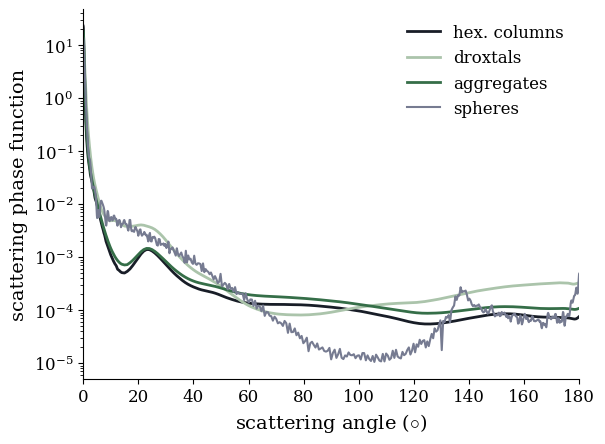

In [8]:
linewidth = 2
c1, c2, c3, c4 = '#181D27', '#ABC4AB', '#356E48', '#767B91'
plt.semilogy(theta_hex, f_hex * phase_hex[i, :, 0], linewidth = linewidth, color = c1, label = "hex. columns")#/phase_hex[i, 0, 0])
plt.semilogy(theta_drox, f_drox * phase_drox[i, :, 0], linewidth = linewidth, color = c2, label = "droxtals")#/phase_drox[i, 0, 0])
plt.semilogy(theta_agg, f_agg * phase_agg[i, :, 0], linewidth = linewidth, color = c3, label ="aggregates")#/phase_agg[i, 0, 0])
plt.semilogy(theta_Mie, f_Mie * phase_Mie[i, :, 0], linewidth = 1.5, color = c4, label = "spheres")#/phase_Mie[i, 0, 0])

plt.legend()

plt.ylabel('scattering phase function')
plt.xlabel('scattering angle ($\\circ$)')
plt.xlim([0, 180])

plt.savefig('figures/phase_functions.png', dpi = 300, bbox_inches = 'tight')
plt.show()


### Fig. 2
Our calculation of the Myhre benchmark.

In [12]:
ecrad_output = xr.open_dataset('../contrails25/results_embed_ecrad.nc').sel(tau_cloud = 0, tau_contrail = 0.3)
ecrad_output.to_netcdf('data/ecrad_benchmark.nc')

ecrad_output_opt = xr.open_dataset('../contrails25/../dephy2ecRad/results_embed_ecrad_cld.nc').sel(tau_cloud = 0, tau_contrail = 0.3)
ecrad_output_opt.to_netcdf('data/ecrad_benchmark_opt.nc')

ecrad_output_lws = xr.open_dataset('../contrails25/../dephy2ecRad/results_embed_ecrad_nolwscat.nc').sel(tau_cloud = 0, tau_contrail = 0.3)
ecrad_output_lws.to_netcdf('data/ecrad_benchmark_nolwscat.nc')

ecrad_output_gpt = xr.open_dataset('../contrails25/../dephy2ecRad/results_embed_ecrad_gptavg.nc').sel(tau_cloud = 0, tau_contrail = 0.3)
ecrad_output_gpt.to_netcdf('data/ecrad_benchmark_gptavg.nc')

rrtmgp = xr.open_dataset('../contrails25/rrtmgp_embed_hex.nc').sel(tau_cloud = 0, tau_contrail = 0.3).isel(level = -1)
rrtmgp.to_netcdf('data/rrtmgp_benchmark.nc')

rrtmgp_opt = xr.open_dataset('../contrails25/rrtmgp_embed_band_cld_2.nc').sel(tau_cloud = 0, tau_contrail = 0.3).isel(level = -1)
rrtmgp_opt.to_netcdf('data/rrtmgp_benchmark_opt.nc')

rrtmgp_lws = xr.open_dataset('../contrails25/rrtmgp_embed_hex_no_lwscat.nc').sel(tau_cloud = 0, tau_contrail = 0.3).isel(level = -1)
rrtmgp_lws.to_netcdf('data/rrtmgp_benchmark_nolwscat.nc')

libradtran = xr.open_dataset('../contrails25/libradtran_embed.nc').sel(zout = 'TOA', tau_cloud = 0, tau_contrail = 0.3)
libradtran.to_netcdf('data/libradtran_benchmark.nc')

libradtran_lws = xr.open_dataset('/homedata/pczarnec/libradtran/Myhre_libradtran_15_nolwscat.nc').sel(zout = 'TOA')
libradtran_lws.to_netcdf('data/libradtran_benchmark_nolwscat.nc')

libradtran_opt = xr.open_dataset('/homedata/pczarnec/libradtran/Myhre_libradtran_15_nonharmonized.nc').sel(zout = 'TOA')
libradtran_opt.to_netcdf('data/libradtran_opt.nc')

Cocip = xr.open_dataset('../contrails25/Myhre_0.3_CoCip.nc')
Cocip.to_netcdf('data/benchmark_cocip.nc')

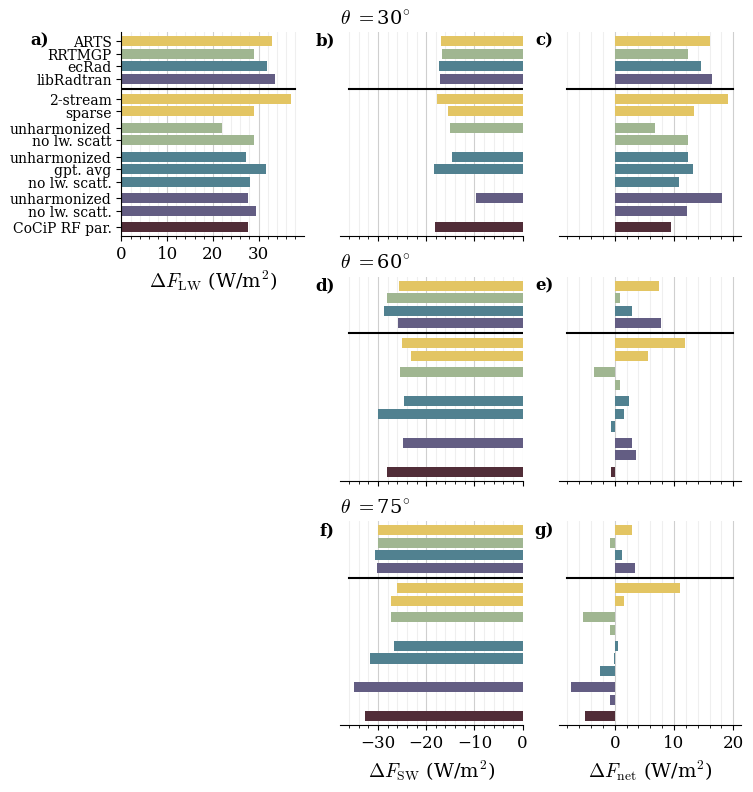

In [ ]:
### now 15 microns

## load data, calculate the CRE
ecrad_output = xr.open_dataset('data/ecrad_benchmark.nc')
LW, SW, _, _ = hf.compute_cre(ecrad_data=ecrad_output)

ecrad_output_opt = xr.open_dataset('data/ecrad_benchmark_opt.nc')
LW_opt, SW_opt, _, _ = hf.compute_cre(ecrad_data=ecrad_output_opt)

ecrad_output_lws = xr.open_dataset('data/ecrad_benchmark_nolwscat.nc')
LW_lws, SW_lws, _, _ = hf.compute_cre(ecrad_data=ecrad_output_lws)

ecrad_output_gpt = xr.open_dataset('data/ecrad_benchmark_gptavg.nc')
LW_gpt, SW_gpt, _, _ = hf.compute_cre(ecrad_data=ecrad_output_gpt)

arts_output_sw = hf.concat_arts_output_batch('data/ARTS_dicts/', 'results_sw_', 'tau_0_tauc_0.3_embed', 'sw', allsky = True)
arts_output_lw = hf.concat_arts_output_batch('data/ARTS_dicts/', 'results_lw_', 'tau_0_tauc_0.3_embed', 'lw', allsky = True)

_, _, LW_ARTS, SW_ARTS = hf.compute_cre(arts_data_sw=arts_output_sw, arts_data_lw=arts_output_lw)

arts_output_sw_2stream = hf.concat_arts_output_batch('data/ARTS_dicts/', 'results_sw_', 'tau_0_tauc_0.3_embed_2stream', 'sw', allsky = True)
arts_output_lw_2stream = hf.concat_arts_output_batch('data/ARTS_dicts/', 'results_lw_', 'tau_0_tauc_0.3_embed_2stream', 'lw', allsky = True)

_, _, LW_ARTS_2stream, SW_ARTS_2stream = hf.compute_cre(arts_data_sw=arts_output_sw_2stream, arts_data_lw=arts_output_lw_2stream)

arts_output_sw_sparser = hf.concat_arts_output_batch('data/ARTS_dicts/', 'results_sw_', 'tau_0_tauc_0.3_embed_sparser', 'sw', allsky = True)
arts_output_lw_sparser = hf.concat_arts_output_batch('data/ARTS_dicts/', 'results_lw_', 'tau_0_tauc_0.3_embed_sparser', 'lw', allsky = True)

_, _, LW_ARTS_sparser, SW_ARTS_sparser = hf.compute_cre(arts_data_sw=arts_output_sw_sparser, arts_data_lw=arts_output_lw_sparser)

rrtmgp = xr.open_dataset('data/rrtmgp_benchmark_nolwscat.nc')
LW_rrtmgp = rrtmgp.lw_flux_up_cs - rrtmgp.lw_flux_up
SW_rrtmgp = rrtmgp.sw_flux_up_cs - rrtmgp.sw_flux_up

rrtmgp_opt = xr.open_dataset('data/rrtmgp_benchmark_opt.nc')
LW_rrtmgp_opt = rrtmgp_opt.lw_flux_up_cs - rrtmgp_opt.lw_flux_up
SW_rrtmgp_opt = rrtmgp_opt.sw_flux_up_cs - rrtmgp_opt.sw_flux_up

rrtmgp_lws = xr.open_dataset('data/rrtmgp_benchmark_nolwscat.nc')
LW_rrtmgp_lws = rrtmgp_lws.lw_flux_up_cs - rrtmgp_lws.lw_flux_up
SW_rrtmgp_lws = rrtmgp_lws.sw_flux_up_cs - rrtmgp_lws.sw_flux_up

libradtran = xr.open_dataset('data/libradtran_benchmark.nc')
LW_libradtran = libradtran.contrail_effect_cre.sel(spectrum = 'lw')
SW_libradtran = libradtran.contrail_effect_cre.sel(spectrum = 'sw')

libradtran_lws = xr.open_dataset('data/libradtran_benchmark_nolwscat.nc')
LW_libradtran_lws = libradtran_lws.eup.sel(tau_cloud = 0, spectrum = 'lw', sza = 0) - libradtran_lws.eup.sel(tau_cloud = 0.3, spectrum = 'lw', sza = 0)
SW_libradtran_lws = (libradtran_lws.eup.sel(tau_cloud = 0, spectrum = 'sw') - libradtran_lws.eup.sel(tau_cloud = 0.3, spectrum = 'sw'))/1000

libradtran_opt = xr.open_dataset('data/libradtran_benchmark_opt.nc')
LW_libradtran_opt = libradtran_opt.eup.sel(tau_cloud = 0, spectrum = 'lw', sza = 0) - libradtran_opt.eup.sel(tau_cloud = 0.3, spectrum = 'lw', sza = 0)
SW_libradtran_opt = (libradtran_opt.eup.sel(tau_cloud = 0, spectrum = 'sw') - libradtran_opt.eup.sel(tau_cloud = 0.3, spectrum = 'sw'))/1000

Cocip = xr.open_dataset('data/cocip_benchmark.nc')

# solar zenith angles
sza = [30., 60., 75.]

### Plot figure
fig, axes = plt.subplots(3, 3, figsize = (8, 9), sharey = True, sharex = 'col') #figsize = (12, 12)
from matplotlib.ticker import MultipleLocator

for idx, ax in enumerate(axes.flatten()):
    ax.xaxis.set_major_locator(MultipleLocator(10))   # <-- major ticks every 10
    ax.xaxis.set_minor_locator(MultipleLocator(2))
    ax.grid(visible = True, which = 'major', axis = 'x', alpha = 0.6)
    ax.grid(visible = True, which = 'minor', axis = 'x', alpha = 0.2)
    ax.set_axisbelow(True)

## set colors, positions of bars
colors = ['#E3C563', '#A0B691', '#518190', '#635D83', '#512D38']
sza_idx = [3, 6, 8]

h_main = 1.5
h_sub = 0.3

ARTS_y = 10
rrtmgp_y = ARTS_y + h_main + 0.2
ecrad_y = rrtmgp_y + h_main + 0.2
pm = 0.3

outline = None   
                      
y_array = -np.array([0, 0.8,  1.8, 0, 3.1, 4.1,  0,  5.4,  6.4,   7.4,  0,  8.7,   9.7, 0, 11   ]) #-np.arange(0.6, 15.6)
main_y = -np.array([-3.8, -2.8, -1.8, -0.8])

### Scroll through each CRE, plot, for each SZA 
for ax_idx in np.arange(3):

    if ax_idx == 0:
        axes[ax_idx, 0].barh(main_y[0], LW_ARTS, edgecolor = outline, color = colors[0])
        axes[ax_idx, 0].barh(y_array[1], LW_ARTS_2stream, color = colors[0])
        axes[ax_idx, 0].barh(y_array[2], LW_ARTS_sparser, color = colors[0])

        axes[ax_idx, 0].barh(main_y[1], LW_rrtmgp, edgecolor = outline, color = colors[1])
        axes[ax_idx, 0].barh(y_array[4], LW_rrtmgp_opt, color = colors[1])
        axes[ax_idx, 0].barh(y_array[5], LW_rrtmgp_lws, color = colors[1])

        axes[ax_idx, 0].barh(main_y[2], LW, edgecolor = outline, color = colors[2])
        axes[ax_idx, 0].barh(y_array[7], LW_opt, color = colors[2])
        axes[ax_idx, 0].barh(y_array[8], LW_gpt, color = colors[2])
        axes[ax_idx, 0].barh(y_array[9], LW_lws, color = colors[2])

        axes[ax_idx, 0].barh(main_y[3], LW_libradtran, color = colors[3], edgecolor = outline)
        axes[ax_idx, 0].barh(y_array[11], LW_libradtran_opt, color = colors[3])
        axes[ax_idx, 0].barh(y_array[12], LW_libradtran_lws, color = colors[3])

        axes[ax_idx, 0].barh(y_array[14], Cocip.rf_cocip_lw[0], color = colors[4])

        axes[ax_idx, 0].plot([0, 38], [-0, -0], color = 'black')
    else:
        axes[ax_idx, 0].set_axis_off()

    axes[ax_idx, 1].barh(main_y[0], SW_ARTS.data[sza_idx[ax_idx]], edgecolor = outline, color = colors[0])
    axes[ax_idx, 1].barh(y_array[1], SW_ARTS_2stream.data[sza_idx[ax_idx]], color = colors[0])
    axes[ax_idx, 1].barh(y_array[2], SW_ARTS_sparser.data[sza_idx[ax_idx]], color = colors[0])

    axes[ax_idx, 1].barh(main_y[1], SW_rrtmgp.data[sza_idx[ax_idx]], edgecolor = outline, color = colors[1])
    axes[ax_idx, 1].barh(y_array[4], SW_rrtmgp_opt.data[sza_idx[ax_idx]], color = colors[1])

    axes[ax_idx, 1].barh(main_y[2], SW.data[sza_idx[ax_idx]], edgecolor = outline, color = colors[2])
    axes[ax_idx, 1].barh(y_array[7], SW_opt.data[sza_idx[ax_idx]], color = colors[2])
    axes[ax_idx, 1].barh(y_array[8], SW_gpt.data[sza_idx[ax_idx]], color = colors[2])

    axes[ax_idx, 1].barh(main_y[3], SW_libradtran[sza_idx[ax_idx]], color = colors[3], edgecolor = outline)
    axes[ax_idx, 1].barh(y_array[11], SW_libradtran_opt[sza_idx[ax_idx]], color = colors[3])

    axes[ax_idx, 1].barh(y_array[14], Cocip.rf_cocip_sw[ax_idx], color = colors[4])


    axes[ax_idx, 1].plot([0, -36], [-0, -0], color = 'black')

    axes[ax_idx, 2].barh(main_y[0], LW_ARTS + SW_ARTS.data[sza_idx[ax_idx]], edgecolor = outline, color = colors[0])
    axes[ax_idx, 2].barh(y_array[1], LW_ARTS_2stream + SW_ARTS_2stream.data[sza_idx[ax_idx]], color = colors[0])
    axes[ax_idx, 2].barh(y_array[2], LW_ARTS_sparser + SW_ARTS_sparser.data[sza_idx[ax_idx]], color = colors[0])

    axes[ax_idx, 2].barh(main_y[1], LW_rrtmgp + SW_rrtmgp.data[sza_idx[ax_idx]], edgecolor = outline, color = colors[1])
    axes[ax_idx, 2].barh(y_array[4], LW_rrtmgp_opt + SW_rrtmgp_opt.data[sza_idx[ax_idx]], color = colors[1])
    axes[ax_idx, 2].barh(y_array[5], LW_rrtmgp_lws + SW_rrtmgp.data[sza_idx[ax_idx]], color = colors[1])

    axes[ax_idx, 2].barh(main_y[2], LW + SW.data[sza_idx[ax_idx]], edgecolor = outline, color = colors[2])
    axes[ax_idx, 2].barh(y_array[7], LW_opt + SW_opt.data[sza_idx[ax_idx]], color = colors[2])
    axes[ax_idx, 2].barh(y_array[8], LW_gpt + SW_gpt.data[sza_idx[ax_idx]], color = colors[2])
    axes[ax_idx, 2].barh(y_array[9], LW_lws + SW.data[sza_idx[ax_idx]], color = colors[2])

    axes[ax_idx, 2].barh(main_y[3], LW_libradtran + SW_libradtran[sza_idx[ax_idx]], color = colors[3], edgecolor = outline)
    axes[ax_idx, 2].barh(y_array[11], LW_libradtran_opt + SW_libradtran_opt[sza_idx[ax_idx]], color = colors[3])
    axes[ax_idx, 2].barh(y_array[12], LW_libradtran_lws + SW_libradtran[sza_idx[ax_idx]], color = colors[3])
    axes[ax_idx, 2].barh(y_array[14], Cocip.rf_cocip_lw[0] + Cocip.rf_cocip_sw[ax_idx], color = colors[4])

    axes[ax_idx, 2].plot([-8, 20], [-0, -0], color = 'black')

    sns.despine(ax=axes[ax_idx, 1], left = True)
    sns.despine(ax=axes[ax_idx, 2], left = True)
    axes[ax_idx, 1].yaxis.set_visible(False)
    axes[ax_idx, 2].yaxis.set_visible(False)

### label figure
axes[ax_idx, 2].set_xlabel("$\\Delta F_{\\mathrm{net}}$ (W/m$^2$)")
axes[ax_idx, 1].set_xlabel("$\\Delta F_{\\mathrm{SW}}$ (W/m$^2$)")
axes[0, 0].set_xlabel("$\\Delta F_{\\mathrm{LW}}$ (W/m$^2$)")
axes[0, 0].tick_params(labelbottom = True)
axes[0, 0].xaxis.set_visible(True)

axes[0, 1].set_title('$\\theta ~=$30$^{\\circ}$', loc = 'left')
axes[1, 1].set_title('$\\theta ~=$60$^{\\circ}$', loc = 'left')
axes[2, 1].set_title('$\\theta ~=$75$^{\\circ}$', loc = 'left')

axes[0, 0].set_yticks(-np.array([-3.8, -2.8, -1.8, -0.8, 0.8,  1.8, 3.1, 4.1, 5.4,  6.4,   7.4, 8.7,   9.7, 11   ]), ['ARTS', 'RRTMGP', 'ecRad', 'libRadtran', '2-stream', 'sparse', 'unharmonized', 'no lw. scatt', 'unharmonized', 'gpt. avg', 'no lw. scatt.', 'unharmonized', 'no lw. scatt.', 'CoCiP RF par.'],
                       fontsize = 10)

labels = ['a)', 'b)', 'c)', '', 'd)', 'e)', '', 'f)', 'g)']
for ax, label in zip(axes.flat, labels):
    if label == 'a)':
        ax.text(-0.4, 1.0, label, transform=ax.transAxes,
            fontsize=12, fontweight='bold', va='top', ha='right')

    else:
        ax.text(-0.03, 1.0, label, transform=ax.transAxes,
                fontsize=12, fontweight='bold', va='top', ha='right')
plt.subplots_adjust(hspace = 0.2)
axes[0, 0].set_ylim([-11.7, 4.5])

### save
plt.savefig('figures/tau_0.3_cloud_diversity.png', dpi = 300, bbox_inches = 'tight')
plt.show()


### Fig. 3-4
Contrail radiative forcing and uncertainty across ice particle habit, contrail optical thickness, and solar zenith angle for $r_{eff} = 15 ~\mu$ m and $r_{eff} = 30~\mu$ m.

In [ ]:
def calc_uncertainty_and_avg(filename, tau_list=None, per_band=False):
    """Calculate the mean contrail radiative forcing and uncertainty
    IN:
        filename [str]
        tau_list [list float]: taus to select (nearest); default = all
        per_band [bool]: if True, the uncertainty is max(|unc_sw|, |unc_lw|) instead of the
                uncertainty of the net effect (as in Myhre et al., 2009).
    OUT:
        uncertainty [fraction]: max spread / mean, with a floor of 1 W/m^2
        avg [W/m^2]: average IRF across the codes
    """
    ds = xr.open_dataset(filename)
    if tau_list is not None:
        ds = ds.sel(tau=tau_list, method='nearest')
 
    def spread(x):
        diff = x.max('model') - x.min('model')
        return diff / np.maximum(1, np.abs(x.mean('model')))
 
    net = ds.sw + ds.lw
    avg = net.mean('model').values
    if per_band:
        unc = np.maximum(np.abs(spread(ds.sw)), np.abs(spread(ds.lw))).values
    else:
        unc = spread(net).values
    return unc, avg

In [24]:
### Calculate uncertainty and average from radiation code outputs

tau_list = [0.05, 0.1, 0.3, 1, 1.5]

unc_15_hex, avg_15_hex = calc_uncertainty_and_avg('data/contrail_hex.nc', tau_list)
unc_15_drox, avg_15_drox = calc_uncertainty_and_avg('data/contrail_drox.nc', tau_list)
unc_15_agg, avg_15_agg = calc_uncertainty_and_avg('data/contrail_agg.nc', tau_list)
unc_15_Mie, avg_15_Mie = calc_uncertainty_and_avg('data/contrail_Mie.nc', tau_list)

unc_30_hex, avg_30_hex = calc_uncertainty_and_avg('data/cloud_hex.nc', tau_list)
unc_30_drox, avg_30_drox = calc_uncertainty_and_avg('data/cloud_drox.nc', tau_list)
unc_30_agg, avg_30_agg = calc_uncertainty_and_avg('data/cloud_agg.nc', tau_list)
unc_30_Mie, avg_30_Mie = calc_uncertainty_and_avg('data/cloud_Mie.nc', tau_list)

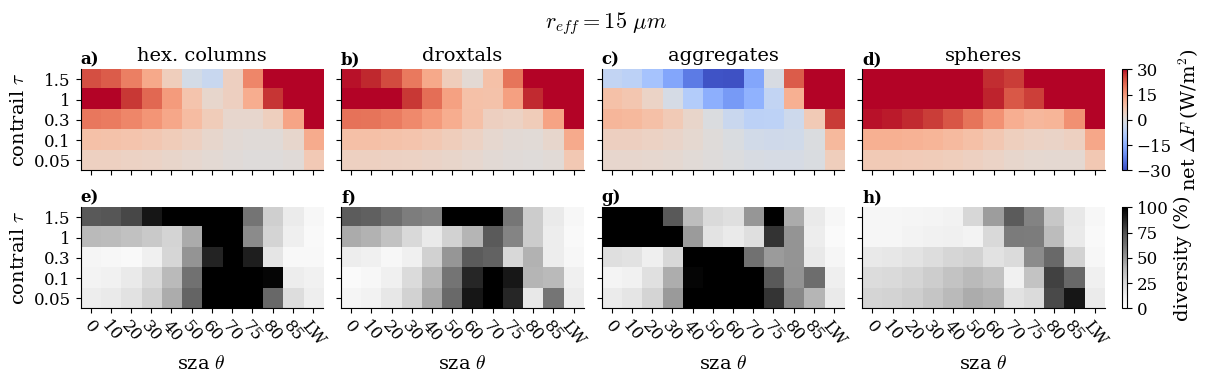

In [28]:
fig, axes = plt.subplots(2, 4, figsize = (12, 5), layout = 'compressed', sharex=True, sharey = True)

szas = np.array([0, 10, 20, 30, 40, 50, 60, 70, 75, 80, 85, 95])
sza_labels = szas
sza_labels = sza_labels.astype(str)
sza_labels[-1] = 'LW'

## hexagons
axes[0, 0].imshow(avg_15_hex, cmap = 'coolwarm', vmin = -30, vmax = 30)
axes[0, 0].set_ylim([-0.5, 4.5])
axes[0, 0].set_yticks(ticks=np.arange(len(tau_list)), labels = tau_list)
axes[0, 0].set_ylabel("contrail $\\tau$")
axes[0, 0].set_title("hex. columns")

axes[1, 0].imshow(100*np.abs(unc_15_hex), cmap = 'Greys', vmin = 0, vmax = 100)
axes[1, 0].set_xticks(ticks=np.arange(len(szas)), labels = sza_labels, rotation=-50)
axes[1, 0].set_ylabel("contrail $\\tau$")
axes[1, 0].set_xlabel("sza $\\theta$")

## droxtals
axes[0, 1].imshow(avg_15_drox, cmap = 'coolwarm', vmin = -30, vmax = 30)
axes[0, 1].set_ylim([-0.5, 4.5])
axes[0, 1].set_title("droxtals")

axes[1, 1].imshow(100*np.abs(unc_15_drox), cmap = 'Greys', vmin = 0, vmax = 100)
axes[1, 1].set_xticks(ticks=np.arange(len(szas)), labels = sza_labels, rotation=-50)
axes[1, 1].set_xlabel("sza $\\theta$")

## aggregates
axes[0, 2].imshow(avg_15_agg, cmap = 'coolwarm', vmin = -30, vmax = 30)
axes[0, 2].set_ylim([-0.5, 4.5])
axes[0, 2].set_title("aggregates")

axes[1, 2].imshow(100*np.abs(unc_15_agg), cmap = 'Greys', vmin = 0, vmax = 100)
axes[1, 2].set_xticks(ticks=np.arange(len(szas)), labels = sza_labels, rotation=-50)
axes[1, 2].set_xlabel("sza $\\theta$")

### Mie
c1 = axes[0, 3].imshow(avg_15_Mie, cmap = 'coolwarm', vmin = -30, vmax = 30)
axes[0, 3].set_ylim([-0.5, 4.5])
axes[0, 3].set_title("spheres")

c2 = axes[1, 3].imshow(100*np.abs(unc_15_Mie), cmap = 'Greys', vmin = 0, vmax = 100)
axes[1, 3].set_xticks(ticks=np.arange(len(szas)), labels = sza_labels, rotation=-50)
axes[1, 3].set_xlabel("sza $\\theta$")

cbar = fig.colorbar(
    c1,
    cax=None,
    orientation='vertical',
    ticks=[-30, -15, 0, 15, 30],
    label = 'net $\\Delta F$ (W/m$^2$)'
)

cbar = fig.colorbar(
    c2,
    cax=None,
    orientation='vertical',
    ticks=[0, 25, 50, 75, 100],
    label = 'diversity (%)'
)

panel_labels = [
    ['a)', 'b)', 'c)', 'd)'],
    ['e)', 'f)', 'g)', 'h)']
]

for i in range(2):
    for j in range(4):

        axes[i, j].text(
            0.0,
            1.05,
            panel_labels[i][j],
            transform=axes[i, j].transAxes,
            fontsize=12,
            fontweight='bold',
            color='black'
        )

plt.suptitle("$r_{eff} = 15~ \\mu m$", y = 0.9)
plt.savefig('figures/raster_15.png', dpi = 300, bbox_inches = 'tight')
plt.show()


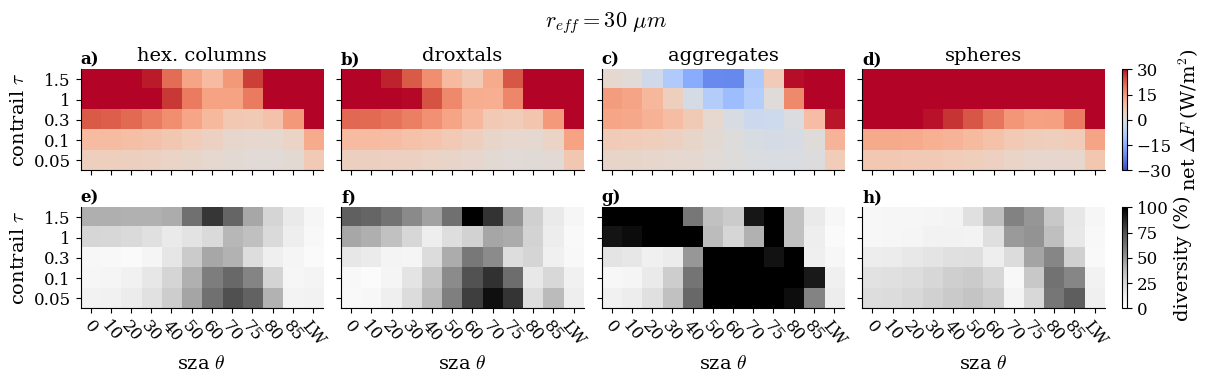

In [29]:
fig, axes = plt.subplots(2, 4, figsize = (12, 5), layout = 'compressed', sharex=True, sharey = True)

szas = np.array([0, 10, 20, 30, 40, 50, 60, 70, 75, 80, 85, 95])
sza_labels = szas
sza_labels = sza_labels.astype(str)
sza_labels[-1] = 'LW'

## hexagons
axes[0, 0].imshow(avg_30_hex, cmap = 'coolwarm', vmin = -30, vmax = 30)
axes[0, 0].set_ylim([-0.5, 4.5])
axes[0, 0].set_yticks(ticks=np.arange(len(tau_list)), labels = tau_list)
axes[0, 0].set_ylabel("contrail $\\tau$")
axes[0, 0].set_title("hex. columns")

axes[1, 0].imshow(100*np.abs(unc_30_hex), cmap = 'Greys', vmin = 0, vmax = 100)
axes[1, 0].set_xticks(ticks=np.arange(len(szas)), labels = sza_labels, rotation=-50)
axes[1, 0].set_ylabel("contrail $\\tau$")
axes[1, 0].set_xlabel("sza $\\theta$")

## droxtals
axes[0, 1].imshow(avg_30_drox, cmap = 'coolwarm', vmin = -30, vmax = 30)
axes[0, 1].set_ylim([-0.5, 4.5])
axes[0, 1].set_title("droxtals")

axes[1, 1].imshow(100*np.abs(unc_30_drox), cmap = 'Greys', vmin = 0, vmax = 100)
axes[1, 1].set_xticks(ticks=np.arange(len(szas)), labels = sza_labels, rotation=-50)
axes[1, 1].set_xlabel("sza $\\theta$")

## aggregates
axes[0, 2].imshow(avg_30_agg, cmap = 'coolwarm', vmin = -30, vmax = 30)
axes[0, 2].set_ylim([-0.5, 4.5])
axes[0, 2].set_title("aggregates")

axes[1, 2].imshow(100*np.abs(unc_30_agg), cmap = 'Greys', vmin = 0, vmax = 100)
axes[1, 2].set_xticks(ticks=np.arange(len(szas)), labels = sza_labels, rotation=-50)
axes[1, 2].set_xlabel("sza $\\theta$")

### Mie
c1 = axes[0, 3].imshow(avg_30_Mie, cmap = 'coolwarm', vmin = -30, vmax = 30)
axes[0, 3].set_ylim([-0.5, 4.5])
axes[0, 3].set_title("spheres")

c2 = axes[1, 3].imshow(100*np.abs(unc_30_Mie), cmap = 'Greys', vmin = 0, vmax = 100)
axes[1, 3].set_xticks(ticks=np.arange(len(szas)), labels = sza_labels, rotation=-50)
axes[1, 3].set_xlabel("sza $\\theta$")

cbar = fig.colorbar(
    c1,
    cax=None,
    orientation='vertical',
    ticks=[-30, -15, 0, 15, 30],
    label = 'net $\\Delta F$ (W/m$^2$)'
)

cbar = fig.colorbar(
    c2,
    cax=None,
    orientation='vertical',
    ticks=[0, 25, 50, 75, 100],
    label = 'diversity (%)'
)

panel_labels = [
    ['a)', 'b)', 'c)', 'd)'],
    ['e)', 'f)', 'g)', 'h)']
]

for i in range(2):
    for j in range(4):

        axes[i, j].text(
            0.0,
            1.05,
            panel_labels[i][j],
            transform=axes[i, j].transAxes,
            fontsize=12,
            fontweight='bold',
            color='black'
        )

plt.suptitle("$r_{eff} = 30~ \\mu m$", y = 0.9)
plt.savefig('figures/raster_30.png', dpi = 300, bbox_inches = 'tight')
plt.show()


### Fig. 6-7
Results from intercomparison in a 24-hour CoCiP run.

In [43]:
def earth_radius(lat):
    '''
    Earth radius from latitude

    In:
    lat: vector or latitudes in degrees  
    
    
    Out:  
    r: vector of radius in meters

    adapted from lgloege/area_grid.py

    '''

    # define oblate spheroid from WGS84
    a = 6378137
    b = 6356752.3142
    e2 = 1 - (b**2/a**2)
    
    # convert from geodecic to geocentric
    # see equation 3-110 in WGS84
    lat = deg2rad(lat)
    lat_gc = np.arctan( (1-e2)*np.tan(lat) )

    # radius equation
    # see equation 3-107 in WGS84
    r = (
        (a * (1 - e2)**0.5) 
         / (1 - (e2 * np.cos(lat_gc)**2))**0.5 
        )

    return r

def area_grid(lat, lon):
    """
    Calculate the area of each grid cell
    Area is in square meters
    
    In:
    lat: vector of latitude in degrees
    lon: vector of longitude in degrees
    
    Out:
    area: grid-cell area in square-meters with dimensions, [lat,lon]
    
    adapted from lgloege/area_grid.py
    """

    xlon, ylat = meshgrid(lon, lat)
    R = earth_radius(ylat)

    dlat = deg2rad(gradient(ylat, axis=0))
    dlon = deg2rad(gradient(xlon, axis=1))

    dy = dlat * R
    dx = dlon * R * cos(deg2rad(ylat))

    area = dy * dx

    return area

### calculate gridded area for weighted spatial averaging
ds = xr.open_dataset('data/ERA5_solstice_with_contrails_1deg_cdt.nc')
grid_area = area_grid(ds.latitude, ds.longitude)
grid_ds = xr.DataArray(grid_area, dims = ["latitude", "longitude"])


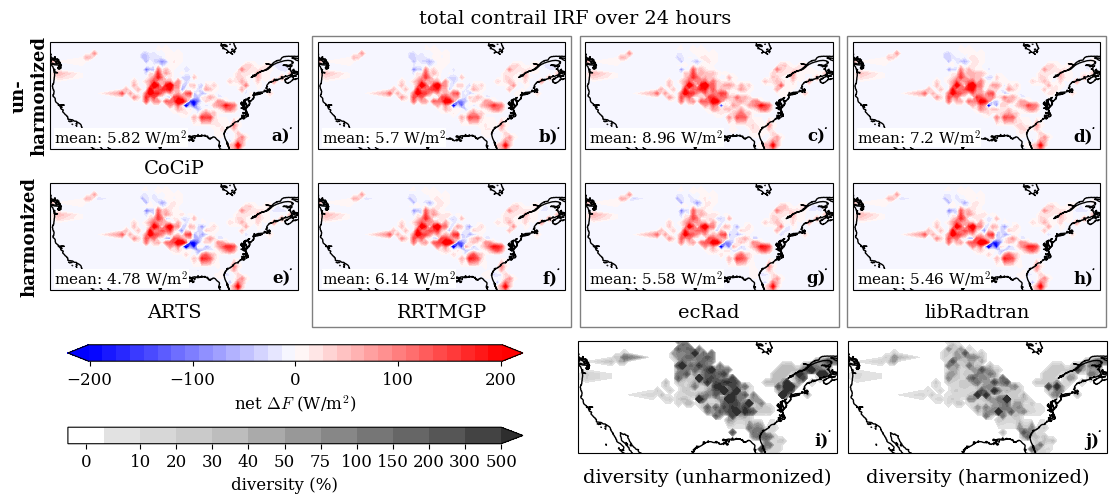

In [49]:
### open data

ecrad = xr.open_dataset('data/ecrad_solstice.nc')
ecrad_nh = xr.open_dataset('data/ecrad_solstice_unharmonized.nc')
rrtmgp_out = xr.open_dataset('data/rrtmgp_solstice.nc')
rrtmgp_out_nh = xr.open_dataset('data/rrtmgp_solstice_unharmonized.nc')
lrt = xr.open_dataset('data/lrt_solstice.nc')
lrt_hex = xr.open_dataset('data/lrt_solstice_unharmonized.nc')
arts = xr.open_dataset('data/arts_solstice.nc')
ds_offline = xr.open_dataset('data/offline_cocip_solstice.nc')


# ============================================================
# Figure layout
# ============================================================

fig = plt.figure(figsize=(14, 5.5))

gs = fig.add_gridspec(
    2, 5,
    width_ratios=[1, 1, 1, 1, 0.06],
    wspace=0.1,
    hspace=-0.5,#-0.57
)

axes = np.empty((2, 4), dtype=object)

for i in range(2):
    for j in range(4):
        axes[i, j] = fig.add_subplot(
            gs[i, j],
            projection=ccrs.PlateCarree()
        )


# ============================================================
# Common colour scale
# ============================================================

norm = colors.TwoSlopeNorm(
    vmin=-200,
    vcenter=0,
    vmax=200
)

levels = np.linspace(-201, 201, 31)

# ============================================================
# NON-HARMONIZED — TOP ROW
# ============================================================

# ------------------------------------------------------------
# a) CoCiP
# ------------------------------------------------------------

axes[0, 0].coastlines()

forcing_cocip = (
    ds_offline["rf_cocip_lw"]
    + ds_offline["rf_cocip_sw"]
)

sc = axes[0, 0].contourf(
    ds.longitude,
    ds.latitude,
    forcing_cocip.sum(dim='time').T,
    cmap='bwr',
    levels=levels,
    norm=norm,
    extend='both'
)

axes[0, 0].set_title(
    "CoCiP",
    y=-0.3
)

forcing_cocip = forcing_cocip.where(forcing_r != 0, np.nan)
forcing_mean = forcing_cocip.sum(dim='time').weighted(grid_ds).mean(dim=["latitude", "longitude"])
axes[0, 0].text(-124, 28.5, 'mean: ' + str(np.round(forcing_mean.data, 2)) + ' W/m$^2$', fontsize = 11,
                bbox=dict(facecolor='white', edgecolor='none', pad=0))



# ------------------------------------------------------------
# b) libRadtran
# ------------------------------------------------------------

axes[0, 3].coastlines()

forcing_lrt_nh = (
    lrt_hex.cre.sel(spectrum="sw", zout="TOA") / 1000
    + lrt_hex.cre.sel(spectrum="lw", zout="TOA")
)

axes[0, 3].contourf(
    ds.longitude,
    ds.latitude,
    forcing_lrt_nh.sum(dim='time'),
    cmap='bwr',
    levels=levels,
    norm=norm,
    extend='both'
)

forcing_lrt_nh = forcing_lrt_nh.where(forcing_r != 0, np.nan)
forcing_mean = forcing_lrt_nh.sum(dim='time').weighted(grid_ds).mean(dim=["latitude", "longitude"])
axes[0, 3].text(-124, 28.5, 'mean: ' + str(np.round(forcing_mean.data, 2)) + ' W/m$^2$', fontsize = 11,
                bbox=dict(facecolor='white', edgecolor='none', pad=0))


#axes[0, 1].set_title(
#    "libRadtran",
#    y=-0.3
#)

# ------------------------------------------------------------
# c) ecRad
# ------------------------------------------------------------

forcing_ecrad_nh = (
    ecrad_nh.flux_up_lw_clear.isel(half_level=0)
    - ecrad_nh.flux_up_lw.isel(half_level=0)
    + ecrad_nh.flux_up_sw_clear.isel(half_level=0)
    - ecrad_nh.flux_up_sw.isel(half_level=0)
)

axes[0, 2].coastlines()

axes[0, 2].contourf(
    ds.longitude,
    ds.latitude,
    forcing_ecrad_nh.sum(dim='time'),
    cmap='bwr',
    levels=levels,
    norm=norm,
    extend='both'
)

forcing_ecrad_nh = forcing_ecrad_nh.where(forcing_r != 0, np.nan)
forcing_mean = forcing_ecrad_nh.sum(dim='time').weighted(grid_ds).mean(dim=["latitude", "longitude"])
axes[0, 2].text(-124, 28.5, 'mean: ' + str(np.round(forcing_mean.data, 2)) + ' W/m$^2$', fontsize = 11,
                bbox=dict(facecolor='white', edgecolor='none', pad=0))


#axes[0, 2].set_title(
#    "ecRad",
#    y=-0.3
#)

# ------------------------------------------------------------
# d) RRTMGP
# ------------------------------------------------------------

forcing_rrtmgp_nh = (
    rrtmgp_out_nh.lw_flux_up_cs.isel(level=-1)
    - rrtmgp_out_nh.lw_flux_up.isel(level=-1)
    + rrtmgp_out_nh.sw_flux_up_cs.isel(level=-1)
    - rrtmgp_out_nh.sw_flux_up.isel(level=-1)
)

axes[0, 1].coastlines()

axes[0, 1].contourf(
    forcing_rrtmgp_nh.longitude,
    forcing_rrtmgp_nh.latitude,
    forcing_rrtmgp_nh.sum(dim='time'),
    cmap='bwr',
    levels=levels,
    norm=norm,
    extend='both'
)

forcing_rrtmgp_nh = forcing_rrtmgp_nh.where(forcing_r != 0, np.nan)
forcing_mean = forcing_rrtmgp_nh.sum(dim='time').weighted(grid_ds).mean(dim=["latitude", "longitude"])
axes[0, 1].text(-124, 28.5, 'mean: ' + str(np.round(forcing_mean.data, 2)) + ' W/m$^2$', fontsize = 11,
                bbox=dict(facecolor='white', edgecolor='none', pad=0))



#axes[0, 3].set_title(
#    "RRTMGP",
#    y=-0.3
#)

# ============================================================
# HARMONIZED — BOTTOM ROW
# ============================================================

# ------------------------------------------------------------
# e) ARTS
# ------------------------------------------------------------

axes[1, 0].coastlines()

forcing_arts = (
    arts.cre.sel(spectrum="sw")
    + arts.cre.sel(spectrum="lw")
)

axes[1, 0].contourf(
    ds.longitude,
    ds.latitude,
    forcing_arts.sum(dim='time'),
    cmap='bwr',
    levels=levels,
    norm=norm,
    extend='both'
)

axes[1, 0].set_title(
    "ARTS",
    y=-0.33
)

forcing_arts.where(forcing_r != 0, np.nan)
forcing_mean = forcing_arts.sum(dim='time').weighted(grid_ds).mean(dim=["latitude", "longitude"])
axes[1, 0].text(-124, 28.5, 'mean: ' + str(np.round(forcing_mean.data, 2)) + ' W/m$^2$', fontsize = 11,
                bbox=dict(facecolor='white', edgecolor='none', pad=0))


# ------------------------------------------------------------
# f) libRadtran
# ------------------------------------------------------------

axes[1, 3].coastlines()

forcing_lrt = (
    lrt.cre.sel(spectrum="sw", zout="TOA") / 1000
    + lrt.cre.sel(spectrum="lw", zout="TOA")
)

axes[1, 3].contourf(
    ds.longitude,
    ds.latitude,
    forcing_lrt.sum(dim='time'),
    cmap='bwr',
    levels=levels,
    norm=norm,
    extend='both'
)

axes[1, 3].set_title(
    "libRadtran",
    y=-0.33
)

forcing_lrt.where(forcing_r != 0, np.nan)
forcing_mean = forcing_lrt.sum(dim='time').weighted(grid_ds).mean(dim=["latitude", "longitude"])
axes[1, 3].text(-124, 28.5, 'mean: ' + str(np.round(forcing_mean.data, 2)) + ' W/m$^2$', fontsize = 11,
                bbox=dict(facecolor='white', edgecolor='none', pad=0))


# ------------------------------------------------------------
# g) ecRad
# ------------------------------------------------------------

forcing_ecrad = (
    ecrad.flux_up_lw_clear.isel(half_level=0)
    - ecrad.flux_up_lw.isel(half_level=0)
    + ecrad.flux_up_sw_clear.isel(half_level=0)
    - ecrad.flux_up_sw.isel(half_level=0)
)

axes[1, 2].coastlines()

axes[1, 2].contourf(
    ecrad.longitude,
    ecrad.latitude,
    forcing_ecrad.sum(dim='time'),
    cmap='bwr',
    levels=levels,
    norm=norm,
    extend='both'
)

axes[1, 2].set_title(
    "ecRad",
    y=-0.33
)

forcing_ecrad = forcing_ecrad.where(forcing_r != 0, np.nan)
forcing_mean = forcing_ecrad.sum(dim='time').weighted(grid_ds).mean(dim=["latitude", "longitude"])
axes[1, 2].text(-124, 28.5, 'mean: ' + str(np.round(forcing_mean.data, 2)) + ' W/m$^2$', fontsize = 11,
                bbox=dict(facecolor='white', edgecolor='none', pad=0))


# ------------------------------------------------------------
# h) RRTMGP
# ------------------------------------------------------------

forcing_rrtmgp = (
    rrtmgp_out.lw_flux_up_cs.isel(level=-1)
    - rrtmgp_out.lw_flux_up.isel(level=-1)
    + rrtmgp_out.sw_flux_up_cs.isel(level=-1)
    - rrtmgp_out.sw_flux_up.isel(level=-1)
)

axes[1, 1].coastlines()

axes[1, 1].contourf(
    forcing_rrtmgp.longitude,
    forcing_rrtmgp.latitude,
    forcing_rrtmgp.sum(dim='time'),
    cmap='bwr',
    levels=levels,
    norm=norm,
    extend='both'
)

axes[1, 1].set_title(
    "RRTMGP",
    y=-0.33
)

forcing_rrtmgp = forcing_rrtmgp.where(forcing_r != 0, np.nan)
forcing_mean = forcing_rrtmgp.sum(dim='time').weighted(grid_ds).mean(dim=["latitude", "longitude"])
axes[1, 1].text(-124, 28.5, 'mean: ' + str(np.round(forcing_mean.data, 2)) + ' W/m$^2$', fontsize = 11,
                bbox=dict(facecolor='white', edgecolor='none', pad=0))


# ============================================================
# Row labels: non-harmonized / harmonized
# ============================================================

# Position based on the first column of maps
pos_top = axes[0, 0].get_position()
pos_bottom = axes[1, 0].get_position()

# x position just to the left of the first column
row_label_x = pos_top.x0 - 0.015

# Vertical centre of each row
top_y = (pos_top.y0 + pos_top.y1) / 2
bottom_y = (pos_bottom.y0 + pos_bottom.y1) / 2

fig.text(
    row_label_x,
    top_y,
    "un-\nharmonized",
    ha='center',
    va='center',
    rotation=90,
    fontsize=13,
    fontweight='bold'
)

fig.text(
    row_label_x,
    bottom_y,
    "harmonized",
    ha='center',
    va='center',
    rotation=90,
    fontsize=13,
    fontweight='bold'
)


# ============================================================
# Overall title
# ============================================================

fig.suptitle(
    'total contrail IRF over 24 hours',
    fontsize=14,
    y=0.78
)

# ============================================================
# Boxes around columns 2, 3, and 4 (now including the code names)
# ============================================================

renderer = fig.canvas.get_renderer()
inv = fig.transFigure.inverted()

for j in [1, 2, 3]:  # columns 2, 3, 4

    # Position of the top and bottom axes in this column
    pos_top = axes[0, j].get_position()
    pos_bottom = axes[1, j].get_position()

    # Lower edge of the code-name title under the bottom map (figure coords)
    title_bbox = axes[1, j].title.get_window_extent(renderer)
    title_y0 = inv.transform((title_bbox.x0, title_bbox.y0))[1]

    # Small padding around each box
    pad_x = 0.004
    pad_y = 0.01

    x0 = pos_top.x0 - pad_x
    y0 = min(pos_bottom.y0, title_y0) - pad_y   # extend down to include the name
    x1 = pos_top.x1 + pad_x
    y1 = pos_top.y1 + pad_y

    rect = Rectangle(
        (x0, y0),
        x1 - x0,
        y1 - y0,
        transform=fig.transFigure,
        fill=False,
        edgecolor='grey',
        linewidth=1,
        zorder=100
    )

    fig.add_artist(rect)

#plt.savefig('Figures/cocip_solstice_timesum.png', dpi = 300, bbox_inches = 'tight')

# ============================================================
# Small, vertically centred colourbar axis
# ============================================================

cax_full = fig.add_axes([0.05, 0.15, 0.5, 0.05])
cax_full.set_visible(False)

pos = cax_full.get_position()

# Colourbar = 60% of total subplot height
cbar_height = 0.6 * pos.height

# Centre vertically
cbar_bottom = pos.y0 + (pos.height - cbar_height) / 2

# Slightly narrower than allocated column
cbar_width = 0.65 * pos.width

# Centre horizontally
cbar_left = pos.x0 + (pos.width - cbar_width) / 2

# Move both colourbars down, further from the boxes
cbar_shift = 0.02

cax = fig.add_axes([
    cbar_left,
    cbar_bottom - cbar_shift,
    cbar_width,
    cbar_height
])

cax2 = fig.add_axes([
    cbar_left,
    cbar_bottom - 0.15 - cbar_shift,
    cbar_width,
    cbar_height
])

# ============================================================
# Colorbar
# ============================================================

cbar = fig.colorbar(
    sc,
    cax=cax,
    orientation='horizontal',
    ticks=[-200, -100, 0, 100, 200]
)

cbar.set_label(
    'net $\\Delta F$ (W/m$^2$)',
    fontsize=12
)


# ============================================================
# Diversity panels (i, j)
# ============================================================

nh_ax = fig.add_axes([0.502, -0.05, x1 - x0, 0.25], projection=ccrs.PlateCarree())
h_ax = fig.add_axes([0.695, -0.05, x1 - x0, 0.25], projection=ccrs.PlateCarree())

max_nh = np.maximum(np.maximum(np.maximum(forcing_cocip.sum(dim='time').T, forcing_rrtmgp_nh.sum(dim='time')), forcing_ecrad_nh.sum(dim='time')), forcing_lrt_nh.sum(dim='time'))
min_nh = np.minimum(np.minimum(np.minimum(forcing_cocip.sum(dim='time').T, forcing_rrtmgp_nh.sum(dim='time')), forcing_ecrad_nh.sum(dim='time')), forcing_lrt_nh.sum(dim='time'))
mean_nh = np.nanmean([forcing_cocip.sum(dim='time').T, forcing_rrtmgp_nh.sum(dim='time'), forcing_ecrad_nh.sum(dim='time'), forcing_lrt_nh.sum(dim='time')], axis = 0)
nh_div = (max_nh - min_nh)/np.maximum(np.ones_like(mean_nh), np.abs(mean_nh))


max_h = np.maximum(np.maximum(np.maximum(forcing_arts.sum(dim='time'), forcing_rrtmgp.sum(dim='time')), forcing_ecrad.sum(dim='time')), forcing_lrt.sum(dim='time'))
min_h = np.minimum(np.minimum(np.minimum(forcing_arts.sum(dim='time'), forcing_rrtmgp.sum(dim='time')), forcing_ecrad.sum(dim='time')), forcing_lrt.sum(dim='time'))
mean_h = np.nanmean([forcing_arts.sum(dim='time'), forcing_rrtmgp.sum(dim='time'), forcing_ecrad.sum(dim='time'), forcing_lrt.sum(dim='time')], axis = 0)
h_div = (max_h - min_h)/np.maximum(np.ones_like(mean_h), np.abs(mean_h))

# ------------------------------------------------------------
# Discrete grey scale, finer steps at the high end.
# Everything above the last level (200 %) shares one "over" colour.
# The darkest shade is capped (0.85) so there is no solid black region.
# ------------------------------------------------------------
div_levels = [0, 10, 20, 30, 40, 50, 75, 100, 150, 200, 300, 500]

# Zero diversity gets its own bin (0 to eps), coloured white.
# eps is tiny, so only (essentially) exact zeros fall in it.
eps = 1e-3
div_edges = [0, eps] + div_levels[1:]
n_grey = len(div_edges) - 1      # grey bins: eps->10, ..., ->500, plus the ">500" bin

# colour 0 = white (zero bin); the rest run light -> dark grey; the last one is ">500"
greys = plt.cm.Greys(np.linspace(0.2, 0.85, n_grey))
div_cmap = colors.ListedColormap([(1, 1, 1, 1)] + list(greys))

# BoundaryNorm maps each bin to its own colour. A plain linear norm would map by
# *value*, which squashes the small, finely spaced bins into the first colour(s).
div_norm = colors.BoundaryNorm(div_edges, ncolors=div_cmap.N, extend='max')

# NaNs are masked by contourf, so they show the axes background: force it to pure white
nh_ax.set_facecolor('white')
h_ax.set_facecolor('white')

nh_ax.coastlines()
h_ax.coastlines()

nh_ax.contourf(
    ecrad.longitude,
    ecrad.latitude,
    100*np.abs(nh_div.data),
    cmap=div_cmap,
    norm=div_norm,
    levels=div_edges,
    extend='max'
)

sc2 = h_ax.contourf(
    ecrad.longitude,
    ecrad.latitude,
    100*np.abs(h_div.data),
    cmap=div_cmap,
    norm=div_norm,
    levels=div_edges,
    extend='max'
)

nh_ax.set_title(
    "diversity (unharmonized)",
    y=-0.33
)

h_ax.set_title(
    "diversity (harmonized)",
    y=-0.33
)

cbar = fig.colorbar(
    sc2,
    cax=cax2,
    orientation='horizontal',
    spacing='uniform'
)
# "0" sits at the centre of the white (zero) bin; the other ticks are bin edges.
# (eps/2 lies inside the first bin, so no separate tick at the eps edge.)
cbar.set_ticks([eps / 2] + div_levels[1:])
cbar.set_ticklabels(['0'] + [str(l) for l in div_levels[1:]])
# the discrete colorbar can add automatic minor ticks (e.g. at the eps edge): remove them
cbar.minorticks_off()
cbar.ax.xaxis.set_minor_locator(plt.NullLocator())
cbar.set_label(
    r'diversity (%)',
    fontsize=12
)

# ============================================================
# a)–j) labels in bottom-right corner of each plot
# ============================================================

panel_labels = [
    ['a)', 'b)', 'c)', 'd)'],
    ['e)', 'f)', 'g)', 'h)']
]

label_kw = dict(
    ha='right',
    va='bottom',
    fontsize=12,
    fontweight='bold',
    color='black'
)

for i in range(2):
    for j in range(4):
        axes[i, j].text(
            0.97, 0.04, panel_labels[i][j],
            transform=axes[i, j].transAxes,
            **label_kw
        )

nh_ax.text(0.97, 0.04, 'i)', transform=nh_ax.transAxes, **label_kw)
h_ax.text(0.97, 0.04, 'j)', transform=h_ax.transAxes, **label_kw)

plt.savefig('figures/cocip_solstice_timesum.png', dpi = 300, bbox_inches = 'tight')

plt.show()

In [ ]:
### Calculate domain- averaged means for Fig. 7
forcing_r = (rrtmgp_out.lw_flux_up_cs.isel(level = -1) - rrtmgp_out.lw_flux_up.isel(level = -1)) + (rrtmgp_out.sw_flux_up_cs.isel(level = -1)                                                                                                           - rrtmgp_out.sw_flux_up.isel(level = -1))
forcing_e = (ecrad.flux_up_lw_clear.isel(half_level = 0) - ecrad.flux_up_lw.isel(half_level = 0)) + (ecrad.flux_up_sw_clear.isel(half_level = 0) - ecrad.flux_up_sw.isel(half_level = 0))
forcing_ol = ds_offline["rf_cocip_lw"] + ds_offline["rf_cocip_sw"]
forcing_arts = arts.cre.sel(spectrum = "sw") + arts.cre.sel(spectrum = "lw")
forcing_lrt = lrt.cre.sel(spectrum = "sw", zout = "TOA")/1000 + lrt.cre.sel(spectrum = "lw", zout = "TOA")
forcing_lrt_nh = lrt_hex.cre.sel(spectrum = "sw", zout = "TOA")/1000 + lrt_hex.cre.sel(spectrum = "lw", zout = "TOA")
forcing_r = (rrtmgp_out.lw_flux_up_cs.isel(level = -1) - rrtmgp_out.lw_flux_up.isel(level = -1)) + (rrtmgp_out.sw_flux_up_cs.isel(level = -1)  - rrtmgp_out.sw_flux_up.isel(level = -1))
forcing_r = forcing_r.where(forcing_r != 0, np.nan)
forcing_r_nh = (rrtmgp_out_nh.lw_flux_up_cs.isel(level = -1) - rrtmgp_out_nh.lw_flux_up.isel(level = -1)) + (rrtmgp_out_nh.sw_flux_up_cs.isel(level = -1)  - rrtmgp_out_nh.sw_flux_up.isel(level = -1))
forcing_r_nh = forcing_r_nh.where(forcing_r_nh != 0, np.nan)
forcing_e = (ecrad.flux_up_lw_clear.isel(half_level = 0) - ecrad.flux_up_lw.isel(half_level = 0)) + (ecrad.flux_up_sw_clear.isel(half_level = 0) - ecrad.flux_up_sw.isel(half_level = 0))
forcing_e = forcing_e.where(forcing_e != 0, np.nan)
forcing_e_nh = (ecrad_nh.flux_up_lw_clear.isel(half_level = 0) - ecrad_nh.flux_up_lw.isel(half_level = 0)) + (ecrad_nh.flux_up_sw_clear.isel(half_level = 0) - ecrad_nh.flux_up_sw.isel(half_level = 0))
forcing_e_nh = forcing_e_nh.where(forcing_e_nh != 0, np.nan)
forcing_ol = ds_offline["rf_cocip_lw"] + ds_offline["rf_cocip_sw"]
forcing_ol = forcing_ol.where(forcing_ol != 0, np.nan)
forcing_arts = arts.cre.sel(spectrum = "sw") + arts.cre.sel(spectrum = "lw")
forcing_arts = forcing_arts.where(forcing_arts != 0, np.nan)
forcing_lrt = lrt.cre.sel(spectrum = "sw", zout = "TOA")/1000 + lrt.cre.sel(spectrum = "lw", zout = "TOA")
forcing_lrt = forcing_lrt.where(forcing_lrt != 0, np.nan)
forcing_lrt_nh = lrt_hex.cre.sel(spectrum = "sw", zout = "TOA")/1000 + lrt_hex.cre.sel(spectrum = "lw", zout = "TOA")
forcing_lrt_nh = forcing_lrt_nh.where(forcing_lrt_nh != 0, np.nan)

In [ ]:
### load profile data
profile = xr.open_dataset('data/solstice_profiles.nc')
ARTS_taus = xr.open_dataset('data/solstice_taus.nc')

iwc_w = profile.q_hydrometeor.isel(hydrometeor = -1).fillna(0)
mean_reff = profile.re_hydrometeor.isel(hydrometeor = -1).weighted(iwc_w).mean(dim = "isobaricInhPa")
all_reff = mean_reff.weighted(grid_ds_cdt).mean(dim=["latitude", "longitude"]) * 1e6
all_taus = (ARTS_taus.ARTS_tau.sum(dim="isobaricInhPa")).weighted(grid_ds).mean(dim=["latitude", "longitude"])
all_sza = profile.sza.weighted(grid_ds_cdt).mean(dim=["latitude", "longitude"])
all_sza = all_sza * (all_sza.data < 90)

In [55]:
### domain- and time- mean averages
af_r = forcing_r.weighted(grid_ds).mean(dim=["latitude", "longitude"])
af_r_nh = forcing_r_nh.weighted(grid_ds).mean(dim=["latitude", "longitude"])
af_e = forcing_e.weighted(grid_ds).mean(dim=["latitude", "longitude"])
af_e_nh = forcing_e_nh.weighted(grid_ds).mean(dim=["latitude", "longitude"])
af_ol = forcing_ol.weighted(grid_ds).mean(dim=["latitude", "longitude"])
af_arts = forcing_arts.weighted(grid_ds).mean(dim=["latitude", "longitude"])
af_lrt = forcing_lrt.weighted(grid_ds).mean(dim=["latitude", "longitude"])
af_lrt_nh = forcing_lrt_nh.weighted(grid_ds).mean(dim=["latitude", "longitude"])

af_r = forcing_r.weighted(grid_ds).mean(dim=["latitude", "longitude"])
af_r_nh = forcing_r_nh.weighted(grid_ds).mean(dim=["latitude", "longitude"])
af_e = forcing_e.weighted(grid_ds).mean(dim=["latitude", "longitude"])
af_e_nh = forcing_e_nh.weighted(grid_ds).mean(dim=["latitude", "longitude"])
af_ol = forcing_ol.weighted(grid_ds).mean(dim=["latitude", "longitude"])
af_arts = forcing_arts.weighted(grid_ds).mean(dim=["latitude", "longitude"])
af_lrt = forcing_lrt.weighted(grid_ds).mean(dim=["latitude", "longitude"])
af_lrt_nh = forcing_lrt_nh.weighted(grid_ds).mean(dim=["latitude", "longitude"])


### among harmonized and non-harmonized codes:
af_r_all = af_r.mean(dim="time").data
af_r_nh_all = af_r_nh.mean(dim="time").data
af_e_all = af_e.mean(dim="time").data
af_e_nh_all = af_e_nh.mean(dim="time").data
af_ol_all = af_ol.mean(dim="time").data
af_arts_all = af_arts.mean(dim="time").data
af_lrt_all = af_lrt.mean(dim="time").data
af_lrt_nh_all = af_lrt_nh.mean(dim="time").data

cocip_array = np.array([af_r_all, af_e_all, af_arts_all, af_lrt_all, ])
cocip_array_nh = np.array([af_r_nh_all, af_e_nh_all, af_ol_all, af_lrt_nh_all])

avg = cocip_array.mean()
diff = np.max(cocip_array) - np.min(cocip_array)
uncertainty = diff/np.abs(avg)
print(100*np.abs(uncertainty))
print(diff)
print(avg)
print("")

avg_nh = cocip_array_nh.mean()
diff_nh = np.max(cocip_array_nh) - np.min(cocip_array_nh)
uncertainty_nh = diff_nh/np.abs(avg_nh)
print(100*np.abs(uncertainty_nh))
print(diff_nh)
print(avg_nh)


11.11166971784144
1.888326715612525
16.994086069535843

21.840098311088614
4.092196198728896
18.7370777385705


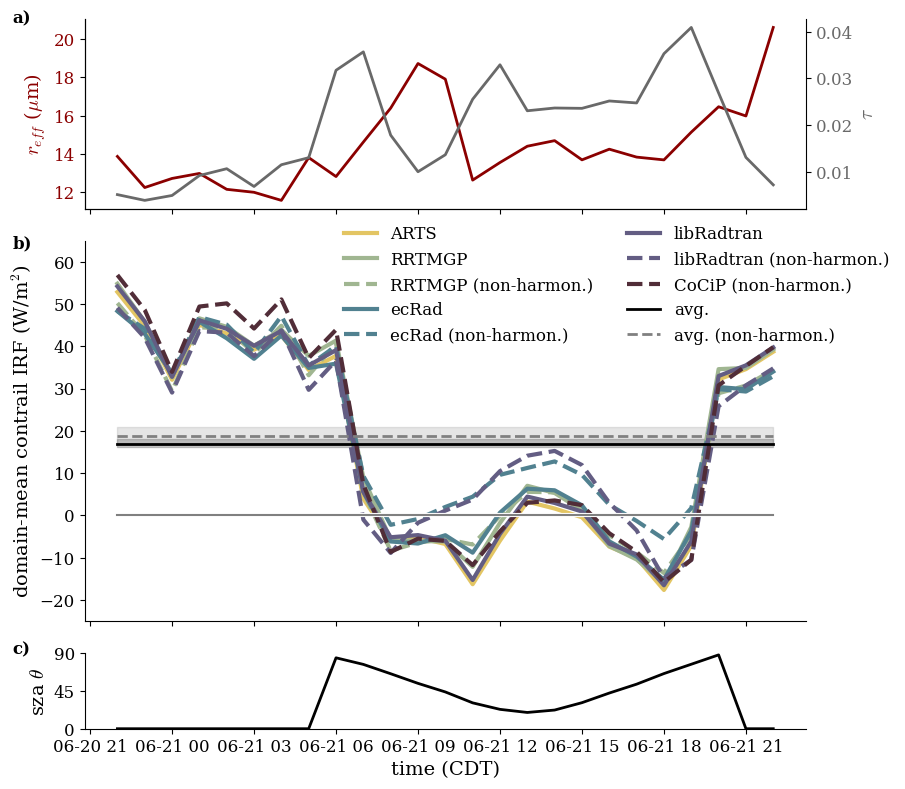

In [56]:
###Plot fig 7
colors = ['#E3C563', '#A0B691', '#518190', '#635D83', '#512D38']

fig, axes = plt.subplots(3, 1, figsize = (9, 8), sharex = True, height_ratios=[0.5, 1, 0.2])

profile = xr.open_dataset('../dephy2ecRad/era5_dephy_contrails_cs_homog.nc').isel(lat = 0, lon = 0)

linewidth = 3
dt = np.timedelta64(5, 'h')

axes[0].plot(af_arts.time - dt, all_reff, color = 'darkred', linewidth = 2)
axes[0].set_ylabel("$r_{eff}$ ($\\mu$m)", color = 'darkred')
axes[0].tick_params(axis='y', labelcolor='darkred')


ax01 = axes[0].twinx()
ax01.plot(af_arts.time - dt, all_taus, color = 'dimgrey', linewidth = 2)
ax01.set_ylabel("$\\tau$", color = 'dimgrey')
axes[0].spines['right'].set_visible(True)
ax01.tick_params(axis='y', labelcolor='dimgrey')


axes[1].plot(af_arts.time - dt, af_arts.data, color = colors[0], label = 'ARTS', linewidth = linewidth)
axes[1].plot(af_r.time - dt, af_r.data, color = colors[1], label = 'RRTMGP', linewidth = linewidth)
axes[1].plot(af_r_nh.time - dt, af_r_nh.data, '--', color = colors[1], label = 'RRTMGP (non-harmon.)', linewidth = linewidth)
axes[1].plot(af_e.time - dt, af_e.data, color = colors[2], label = 'ecRad', linewidth = linewidth)
axes[1].plot(af_e_nh.time - dt, af_e_nh.data, '--', color = colors[2], label = 'ecRad (non-harmon.)', linewidth = linewidth)
axes[1].plot(af_lrt.time - dt, af_lrt.data, color = colors[3], label = 'libRadtran', linewidth = linewidth)
axes[1].plot(af_lrt_nh.time - dt, af_lrt_nh.data, '--', color = colors[3], label = 'libRadtran (non-harmon.)', linewidth = linewidth)
axes[1].plot(af_ol.time - dt, af_ol.data, '--', color = colors[4], label = 'CoCiP (non-harmon.)', linewidth = linewidth)

axes[1].plot(af_r.time - dt, 0*af_r.data, color = 'white', linewidth = linewidth)
axes[1].plot(af_r.time - dt, 0*af_r.data, color = 'grey')

axes[1].set_ylabel("domain-mean contrail IRF (W/m$^2$)")
axes[1].set_ylim([-25, 65])

axes[2].plot(af_arts.time - dt, all_sza, color = 'black', label = 'sza', linewidth = 2)
axes[2].set_xlabel("time (CDT)")
axes[2].set_ylim([0, 90])
axes[2].set_yticks([0, 45, 90])
axes[2].set_ylabel("sza $\\theta$")

panel_labels = [
    'a)', 'b)', 'c)'
]

for i in range(3):
    axes[i].text(
        -0.1,
        0.98,
        panel_labels[i],
        transform=axes[i].transAxes,
        fontsize=12,
        fontweight='bold',
        color='black'
    )


plt.tight_layout()

axes[1].plot(af_arts.time - dt, avg*np.ones(len(af_arts.time.data)), color = 'black', linewidth = 2, label = 'avg.')
axes[1].fill_between(af_arts.time - dt, np.max(cocip_array), np.min(cocip_array), color = 'black', alpha = 0.2)

axes[1].plot(af_arts.time - dt, avg_nh*np.ones(len(af_arts.time.data)), '--', color = 'grey', linewidth = 2, label = 'avg. (non-harmon.)')
axes[1].fill_between(af_arts.time - dt, np.max(cocip_array_nh), np.min(cocip_array_nh), color = 'grey', alpha = 0.2)

axes[1].legend(ncol = 2, loc = (0.35, 0.71), fontsize = 12) #loc=(0.5, 0.8)

plt.savefig('figures/cocip_solstice_domainmean.png', dpi = 300, bbox_inches = 'tight')

plt.show()